<a href="https://colab.research.google.com/github/anacvetkoo/MOS-projekt/blob/main/notebooks/Ziva_teden5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Živa – Analiza RV3 in RV5

**Projekt:** Ali se študij danes še splača?

**RV3 – Stroški študija:** Analiziram spremembe šolnin, skupnih stroškov in neto cen na ameriških univerzah, posebej na Ivy League. Upoštevam inflacijo, preverjam odstopanja in rezultate primerjam z obstoječo raziskavo.

**RV5 – Trg dela:** Analiziram zaslužke in brezposelnost glede na izobrazbo ter povezavo med starostjo in zaslužki v računalniških poklicih v ZDA.

**Podatkovni viri:**
- IPEDS in College Scorecard – RV3
- CPI-U (FRED) – inflacija
- IPUMS USA / ACS 2024 – RV5

In [34]:
# Priprava okolja in povezava z Google Drive
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

# Mapa s podatki in mapa za shranjevanje grafov
mapa = Path("/content/drive/MyDrive/FERI/3. letnik/1. semester/MOS/Projekt")
mapa_figures = mapa / "figures"

if not mapa.is_dir():
    raise FileNotFoundError(f"Mapa ni najdena: {mapa}")
mapa_figures.mkdir(exist_ok=True)

print("Podatkovna mapa:", mapa)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Podatkovna mapa: /content/drive/MyDrive/FERI/3. letnik/1. semester/MOS/Projekt


In [35]:
# Priprava okolja za Plotly in shranjevanje PNG

%pip install -q "plotly==7.1.0" "kaleido==1.5.0"

import kaleido
kaleido.get_chrome_sync()

PosixPath('/root/.local/share/choreographer/deps/chrome-linux64/chrome')



---



## RV3 – Stroški študija

**Vprašanje:** Kako so se spreminjali stroški študija ob upoštevanju inflacije?

- **IPEDS:** `IPEDS_RV3.csv` in `IPEDS_institucije_2004_2024.csv` (pripravila Ana). Šolnine treh skupin univerz, 2004–2023.
- **College Scorecard:** `Scorecard_Ivy_2009_2023.csv` (pripravljeno v pomožnem zvezku). Neto cene in ocenjene skupne stroške sem časovno uskladila z IPEDS; analiza Ivy League zajema študijska leta 2008/09–2022/23.
- **Inflacija:** letno povprečje CPI-U iz FRED. Realni zneski so izraženi v dolarjih leta 2023.
- **Metoda:** Vsako leto računam mediano institucionalnih vrednosti. Vsaka univerza ima enako težo (brez uteževanja po številu študentov).

In [36]:
# RV3: Branje podatkov o šolninah in skupinah univerz

df_ipeds = pd.read_csv(
    mapa / "IPEDS_RV3.csv",
    usecols=["UNITID", "leto", "CHG2AY3", "CHG3AY3"]
)
# CHG2AY3 - šolnina in obvezne pristojbine za študente iz iste zvezne države
# CHG3AY3 - šolnina in obvezne pristojbine za študente iz drugih zveznih držav

df_ipeds_institucije = pd.read_csv(
    mapa / "IPEDS_institucije_2004_2024.csv",
    usecols=["UNITID", "leto", "SECTOR"]
)
# SECTOR - vrsta univerze

# Slovar - identifikatorji + imena univerz Ivy League
ivy_imena = {
    217156: "Brown",
    190150: "Columbia",
    190415: "Cornell",
    182670: "Dartmouth",
    166027: "Harvard",
    186131: "Princeton",
    215062: "UPenn",
    130794: "Yale"
}
ivy_unitid = list(ivy_imena)

print("Zapisi o šolninah:", len(df_ipeds))
print("Obdobje:", df_ipeds["leto"].min(), "–", df_ipeds["leto"].max())

Zapisi o šolninah: 88205
Obdobje: 2004 – 2023


In [37]:
# RV3: Povezovanje podatkov in določitev treh skupin

# Povežem šolnine in vrsto univerze po UNITID in letu
df_rv3_cene = df_ipeds.merge(
    df_ipeds_institucije,
    on=["UNITID", "leto"], how="left", validate="one_to_one"
)
assert df_rv3_cene["SECTOR"].notna().all(), "Manjka oznaka SECTOR."

# SECTOR 1 = javne, 2 = zasebne neprofitne štiriletne univerze
df_rv3_cene = df_rv3_cene[df_rv3_cene["SECTOR"].isin([1, 2])].copy()
df_rv3_cene["Skupina"] = df_rv3_cene["SECTOR"].map({
    1: "Javne štiriletne",
    2: "Druge zasebne neprofitne"
})
df_rv3_cene.loc[df_rv3_cene["UNITID"].isin(ivy_unitid), "Skupina"] = "Ivy League"

# Za javne uporabim in-state šolnino, za zasebne objavljeno šolnino
df_rv3_cene["Solnina_USD"] = np.where(
    df_rv3_cene["SECTOR"] == 1,
    df_rv3_cene["CHG2AY3"],
    df_rv3_cene["CHG3AY3"]
)

# Preverim, koliko šolnin je neveljavnih
neveljavne = (
    df_rv3_cene["Solnina_USD"].isna() | (df_rv3_cene["Solnina_USD"] <= 0)
)
print("Izločene šolnine:", neveljavne.sum())

# Izločim manjkajoče, ničelne in negativne vrednosti
df_rv3_cene = df_rv3_cene[df_rv3_cene["Solnina_USD"] > 0].copy()

print("Veljavnih zapisov:", len(df_rv3_cene))
print(df_rv3_cene["Skupina"].value_counts())

Izločene šolnine: 7443
Veljavnih zapisov: 39916
Skupina
Druge zasebne neprofitne    26144
Javne štiriletne            13612
Ivy League                    160
Name: count, dtype: int64


In [38]:
# RV3: Preverjanje šolnin pri zasebnih neprofitnih univerzah

zasebne = df_rv3_cene[df_rv3_cene["SECTOR"] == 2].copy()

# Primerjam samo zapise, kjer sta na voljo obe šolnini
obe = zasebne.dropna(subset=["CHG2AY3", "CHG3AY3"])

razlike = obe[
    ~np.isclose(obe["CHG2AY3"], obe["CHG3AY3"], atol=0.01)
]

print("Zapisov z obema šolninama:", len(obe))
print("Zapisov z različnima šolninama:", len(razlike))

display(
    razlike[["UNITID", "leto", "Skupina", "CHG2AY3", "CHG3AY3"]].head(10)
)

Zapisov z obema šolninama: 26304
Zapisov z različnima šolninama: 78


,UNITID,leto,Skupina,CHG2AY3,CHG3AY3
1897,180647,2004,Druge zasebne neprofitne,4965.0,11841.0
2662,205203,2004,Druge zasebne neprofitne,11872.0,12030.0
3739,243568,2004,Druge zasebne neprofitne,6220.0,6390.0
6493,180647,2005,Druge zasebne neprofitne,5145.0,12381.0
7250,205203,2005,Druge zasebne neprofitne,13392.0,14444.0
11044,180647,2006,Druge zasebne neprofitne,5361.0,9933.0
11804,205203,2006,Druge zasebne neprofitne,14198.0,15286.0
15601,180647,2007,Druge zasebne neprofitne,5469.0,10041.0
20161,180647,2008,Druge zasebne neprofitne,5613.0,10329.0
24755,180647,2009,Druge zasebne neprofitne,5967.0,10863.0


In [39]:
print("Razlike pri Ivy League:",
      (razlike["Skupina"] == "Ivy League").sum())

print("Razlike pri drugih zasebnih neprofitnih:",
      (razlike["Skupina"] == "Druge zasebne neprofitne").sum())

Razlike pri Ivy League: 0
Razlike pri drugih zasebnih neprofitnih: 78


### Preverjanje šolnin pri zasebnih neprofitnih univerzah

Preverila sem, ali sta `CHG2AY3` in `CHG3AY3` enaki. Pri Ivy League razlik ni bilo, pri drugih zasebnih neprofitnih univerzah pa so se pojavile pri samo 0,3 % zapisov.

Zato sem obdržala obstoječo izbiro `CHG3AY3` za zasebne in `CHG2AY3` za javne univerze.

In [40]:
# RV3: Priprava letnega indeksa inflacije CPI-U

# FRED objavlja mesečni CPI-U; pretvorim ga v letno povprečje
url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=CPIAUCNS"
df_cpi = pd.read_csv(url)

# Ime datumskega stolpca je lahko observation_date ali DATE
stolpec_datuma = "observation_date" if "observation_date" in df_cpi.columns else "DATE"
df_cpi["leto"] = pd.to_datetime(df_cpi[stolpec_datuma]).dt.year

# Za posaezno leto izračunam povprečje njegovih mesečnih vrednosti CPI (ker primerjam letne šolnine)
df_cpi_letni = df_cpi.groupby("leto", as_index=False)["CPIAUCNS"].mean()
df_cpi_letni = df_cpi_letni[df_cpi_letni["leto"].between(2004, 2023)].copy()
df_cpi_letni = df_cpi_letni.rename(columns={"CPIAUCNS": "CPI"})

assert len(df_cpi_letni) == 20 and df_cpi_letni["CPI"].notna().all(), "Preveri CPI."

# Izberem referenčno leto 2023
cpi_2023 = df_cpi_letni.loc[df_cpi_letni["leto"] == 2023, "CPI"].iloc[0]
print("CPI: 2004–2023; referenčno leto: 2023")

CPI: 2004–2023; referenčno leto: 2023


### 1. Primerjava šolnin treh skupin univerz (2004–2023)

Najprej izračunam **nominalno in realno rast mediane šolnin**. Nato preverim, koliko na primerjavo vpliva to, da nabor univerz skozi čas ni enak.

In [41]:
# RV3: Mediane šolnin in rast po skupinah

# Mediana šolnin in število univerz za vsako leto
df_rv3_trend = df_rv3_cene.groupby(["leto", "Skupina"]).agg(
    mediana_solnine=("Solnina_USD", "median"),
    stevilo_univerz=("UNITID", "nunique")
).reset_index()

# Upoštevanje inflacije
df_rv3_trend = df_rv3_trend.merge(df_cpi_letni, on="leto", validate="many_to_one")
# Preračun nominalne šolnine v dolarje z vrednostjo leta 2023
df_rv3_trend["realna_solnina"] = (
    df_rv3_trend["mediana_solnine"] * cpi_2023 / df_rv3_trend["CPI"]
)

# Primerjam začetno in končno leto
pregled_rv3 = df_rv3_trend[df_rv3_trend["leto"].isin([2004, 2023])].pivot(
    index="Skupina",
    columns="leto",
    values=["mediana_solnine", "realna_solnina", "stevilo_univerz"]
)
pregled_rv3.columns = [
    "Nominalno_2004", "Nominalno_2023", "Realno_2004", "Realno_2023",
    "Univerze_2004", "Univerze_2023"
]

# Izračun nominalne in realne (vrednosti prilagojene za inflacijo) rasti
pregled_rv3["Nominalna_rast_pct"] = (
    (pregled_rv3["Nominalno_2023"] / pregled_rv3["Nominalno_2004"] - 1) * 100
).round(1)
pregled_rv3["Realna_rast_pct"] = (
    (pregled_rv3["Realno_2023"] / pregled_rv3["Realno_2004"] - 1) * 100
).round(1)

display(pregled_rv3[["Univerze_2004", "Univerze_2023", "Nominalna_rast_pct", "Realna_rast_pct"]])

# Kontrola: vseh osem univerz Ivy League mora biti prisotnih v vseh letih
ivy = df_rv3_trend[df_rv3_trend["Skupina"] == "Ivy League"]
assert len(ivy) == 20 and (ivy["stevilo_univerz"] == 8).all()

,Univerze_2004,Univerze_2023,Nominalna_rast_pct,Realna_rast_pct
Skupina,,,,
Druge zasebne neprofitne,1276.0,1309.0,98.2,22.8
Ivy League,8.0,8.0,115.7,33.7
Javne štiriletne,596.0,777.0,90.6,18.1


**Kaj pokaže osnovna primerjava?**

- Realna rast šolnin med letoma 2004 in 2023: **Ivy League +33,7 %**, druge zasebne neprofitne **+22,8 %**, javne štiriletne **+18,1 %**.
- Nominalna rast je bila višja v vseh treh skupinah; šolnine so torej zrasle tudi po upoštevanju inflacije.
- **Pozor:** število univerz se skozi čas spreminja. Razlike v rasti lahko odražajo tudi spremembo sestave skupin.

In [42]:
# RV3: Dodatno preverjanje – isti nabor univerz v letih 2004 in 2023

# Obdržim samo začetno in končno leto
krajni_leti = df_rv3_cene[df_rv3_cene["leto"].isin([2004, 2023])].copy()

# Poiščem univerze, ki so v isti skupini prisotne v obeh letih
isti_nabor = krajni_leti.groupby(["UNITID", "Skupina"])["leto"].nunique()
isti_nabor = isti_nabor[isti_nabor == 2].index
krajni_leti = krajni_leti.set_index(["UNITID", "Skupina"]).loc[isti_nabor].reset_index()

# Izračunam mediane
rast_stalni = krajni_leti.groupby(["Skupina", "leto"])["Solnina_USD"].median().unstack()  # .unstack() preoblikuje tabelo, da sta 2004 in 2023 v ločenih stolpcih
rast_stalni["Univerze"] = krajni_leti.groupby("Skupina")["UNITID"].nunique() # koliko univerz je v vsaki skupini

# Ponovno izračunam realno rast, tokrat samo za stalni nabor univerz
cpi_2004 = df_cpi_letni.loc[df_cpi_letni["leto"] == 2004, "CPI"].iloc[0]
rast_stalni["Realna_rast_pct"] = (
    (rast_stalni[2023] / rast_stalni[2004]) * (cpi_2004 / cpi_2023) - 1
) * 100

display(rast_stalni[["Univerze", "Realna_rast_pct"]].round(1))

leto,Univerze,Realna_rast_pct
Skupina,,
Druge zasebne neprofitne,1069,31.3
Ivy League,8,33.7
Javne štiriletne,565,32.5


**Kaj pove preverjanje istega nabora?**

- Med istimi univerzami v letih **2004 in 2023** je realna rast znašala: **Ivy League +33,7 % (8)**, druge zasebne neprofitne **+31,3 % (1.069)** in javne štiriletne **+32,5 % (565)**.
- Razlike med skupinami so **veliko manjše** kot pri prvotni primerjavi vseh razpoložljivih univerz.
- **Sklep:** Ivy League ima v tej preverbi le nekoliko višjo rast; trditev, da se je podražila bistveno hitreje, ni dovolj trdna.
- **Pomen »isti nabor«:** gre za univerze z veljavno šolnino v **obeh končnih letih**, ne nujno za univerze z neprekinjenimi podatki v vseh 20 letih.

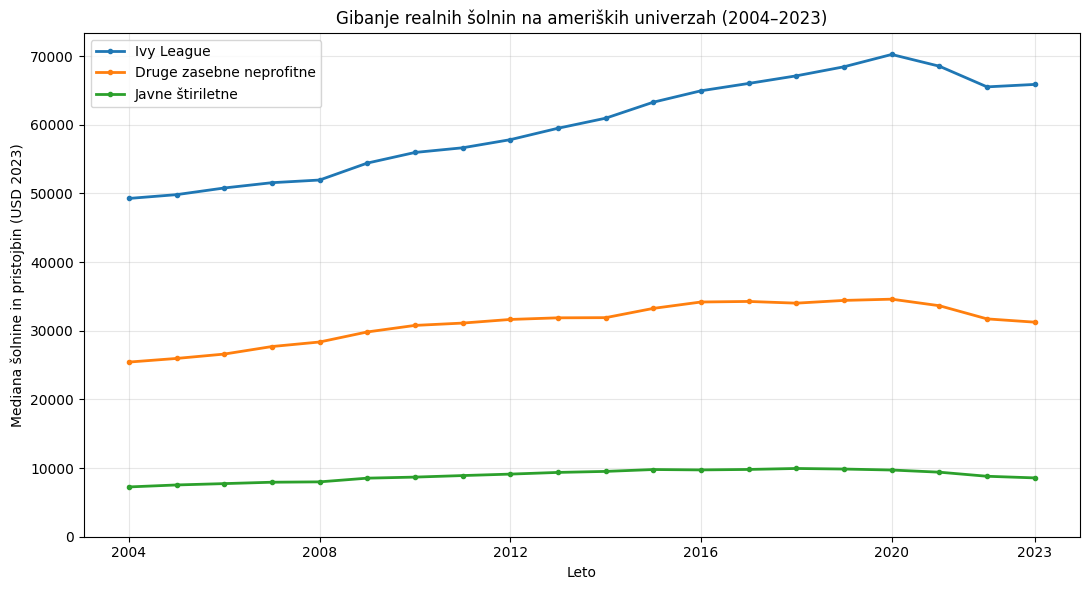

In [43]:
# RV3: Graf realnih šolnin treh skupin univerz

plt.figure(figsize=(11, 6))

skupine = ["Ivy League", "Druge zasebne neprofitne", "Javne štiriletne"]
for skupina in skupine:
    podatki = df_rv3_trend[df_rv3_trend["Skupina"] == skupina]
    plt.plot(
        podatki["leto"], podatki["realna_solnina"],
        marker="o", markersize=3, linewidth=2, label=skupina
    )

plt.title("Gibanje realnih šolnin na ameriških univerzah (2004–2023)")
plt.xlabel("Leto")
plt.ylabel("Mediana šolnine in pristojbin (USD 2023)")
plt.xticks([2004, 2008, 2012, 2016, 2020, 2023])
plt.ylim(bottom=0)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Shranim realni graf v Google Drive
plt.savefig(mapa_figures / "RV3_trend_skupine_2004_2023_realno.png", dpi=300)
plt.show()

**Interpretacija grafa:**

- Prikazuje **mediane šolnin v dolarjih leta 2023** – inflacija je že upoštevana.
- Ivy League ima skozi obdobje bistveno **višjo raven šolnin**; to pa še ne pomeni bistveno **hitrejše odstotne rasti**.
- Graf za vsako leto vključuje vse univerze z veljavnimi podatki. Razlika v rasti med skupinami je zato občutljiva na sestavo vzorca (glej preverbo zgoraj).

### 2. Šolnine, skupni stroški in neto cene Ivy League (2008–2022)

V tem delu analiziram gibanje treh kazalnikov:

- **Šolnina (`Solnina_USD`):** objavljena letna šolnina in obvezne pristojbine, brez življenjskih stroškov.
- **Skupni stroški (`COSTT4_A`):** ocenjeni letni stroški študija (šolnina, bivanje, prehrana in drugi izdatki).
- **Neto cena (`NPT4_PRIV`):** povprečna letna cena po odšteti nepovratni finančni pomoči za redne, prvič vpisane dodiplomske študente, ki prejemajo pomoč Title IV.

**Metoda:** `NPT4_PRIV` je najprej povprečje znotraj posamezne univerze za navedeno skupino študentov. Nato iz osmih institucionalnih vrednosti izračunam mediano med univerzami.

**Namen:** Primerjati šolnine, skupne stroške in neto cene ob upoštevanju inflacije.

In [44]:
# RV3: Priprava podatkov Ivy League (College Scorecard + IPEDS)

# College Scorecard: neto cena in ocenjeni skupni stroški
df_neto_ivy = pd.read_csv(
    mapa / "Scorecard_Ivy_2009_2023.csv",
    usecols=["UNITID", "leto", "NPT4_PRIV", "COSTT4_A"]
)

# IPEDS: šolnine Ivy League
df_ivy_solnine = df_rv3_cene[
    df_rv3_cene["Skupina"] == "Ivy League"
][["UNITID", "leto", "Solnina_USD"]]

In [45]:
# RV3: Preverjanje časovne usklajenosti podatkov

# Ohranimo izvorno leto College Scorecard
df_neto_usklajeno = df_neto_ivy.rename(
    columns={"leto": "leto_scorecard"}
).copy()

# Podatki iz College Scorecard se nanašajo na predhodno študijsko leto.
# Zato leto zmanjšam za 1, da podatke uskladim z IPEDS.
df_neto_usklajeno["leto"] = (
    df_neto_usklajeno["leto_scorecard"] - 1
)

# Povežemo s šolninami za isto študijsko leto
df_ivy_usklajeno = df_neto_usklajeno.merge(
    df_ivy_solnine,
    on=["UNITID", "leto"],
    validate="one_to_one"
)

print("Število zapisov:", len(df_ivy_usklajeno))
print("Obdobje:", df_ivy_usklajeno["leto"].min(),
      "–", df_ivy_usklajeno["leto"].max())

# Preverimo primer UPenn za študijsko leto 2021/22
display(
    df_ivy_usklajeno[
        (df_ivy_usklajeno["UNITID"] == 215062) &
        (df_ivy_usklajeno["leto"] == 2021)
    ]
)

# Za nadaljnje analize uporabim časovno usklajene podatke
df_ivy_stroski = df_ivy_usklajeno.copy()

Število zapisov: 120
Obdobje: 2008 – 2022


,UNITID,NPT4_PRIV,COSTT4_A,leto_scorecard,leto,Solnina_USD
110,215062,26138.0,83298.0,2022,2021,61710.0


In [46]:
# RV3: Shranjevanje časovno usklajenih podatkov Ivy League

df_ivy_stroski.to_csv(
    mapa / "RV3_ivy_stroski_2008_2022.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Podatki uspešno shranjeni.")

Podatki uspešno shranjeni.


In [47]:
# RV3: Letne mediane treh stroškovnih kazalnikov in rast

kazalniki = {
    "Šolnina": "Solnina_USD",
    "Skupni stroški": "COSTT4_A",
    "Neto cena": "NPT4_PRIV"
}

# Mediane osmimh univerz za vsako leto
df_ivy_trend = df_ivy_stroski.groupby(
    "leto", as_index=False
)[list(kazalniki.values())].median()

# Dodam podatke o inflaciji
df_ivy_trend = df_ivy_trend.merge(df_cpi_letni, on="leto", validate="one_to_one")

# Vsak kazalnik preračunam v USD leta 2023 (realne mediane)
for stolpec in kazalniki.values():
    df_ivy_trend[stolpec + "_realno"] = (
        df_ivy_trend[stolpec] * cpi_2023 / df_ivy_trend["CPI"]
    )

# Izberem mediane za leti 2008 in 2022 za izračun rasti
prvo = df_ivy_trend[df_ivy_trend["leto"] == 2008].iloc[0]
zadnje = df_ivy_trend[df_ivy_trend["leto"] == 2022].iloc[0]

pregled_ivy = pd.DataFrame([
    {
        "Kazalnik": ime,
        "Nominalna rast (%)": round((zadnje[s] / prvo[s] - 1) * 100, 1),
        "Realna rast (%)": round((zadnje[s + "_realno"] / prvo[s + "_realno"] - 1) * 100, 1)
    }
    for ime, s in kazalniki.items()
])
display(pregled_ivy)

,Kazalnik,Nominalna rast (%),Realna rast (%)
0,Šolnina,71.4,26.1
1,Skupni stroški,66.9,22.8
2,Neto cena,60.0,17.7


**Kaj kaže primerjava 2008–2022?**

- Realna rast šolnin Ivy League je znašala **26,1 %**, skupnih stroškov **22,8 %**, neto cen pa **17,7 %**.
- Vsi trije kazalniki so se povečali tudi po upoštevanju inflacije.
- Neto cene so bolj nihale, zato posebej preverim, kako izbira začetnega leta vpliva na rezultate.

In [48]:
# RV3: Kako izbira začetnega leta vpliva na rast realnih neto cen?

neto = df_ivy_trend.set_index("leto")["NPT4_PRIV_realno"]
rezultati = []

for leto in [2008, 2009, 2010, 2011]:
    rast = (neto.loc[2022] / neto.loc[leto] - 1) * 100
    rezultati.append({
        "Začetno leto": leto,
        "Realna rast do 2022 (%)": round(rast, 1)
    })

display(pd.DataFrame(rezultati))

,Začetno leto,Realna rast do 2022 (%)
0,2008,17.7
1,2009,30.6
2,2010,-4.6
3,2011,-4.7


**Ugotovitve – vpliv izbire začetnega leta na neto cene**

- Realna rast neto cen do leta 2022 je odvisna od začetnega leta: od leta 2008 znaša **+17,7 %**, od 2009 **+30,6 %**, od 2010 **−4,6 %** in od 2011 **−4,7 %**.
- Neto cene so skozi obdobje precej nihale, zato je rezultat močno odvisen od izbranega začetnega leta.
- Iz podatkov ne morem zanesljivo ugotoviti vzrokov teh nihanj.

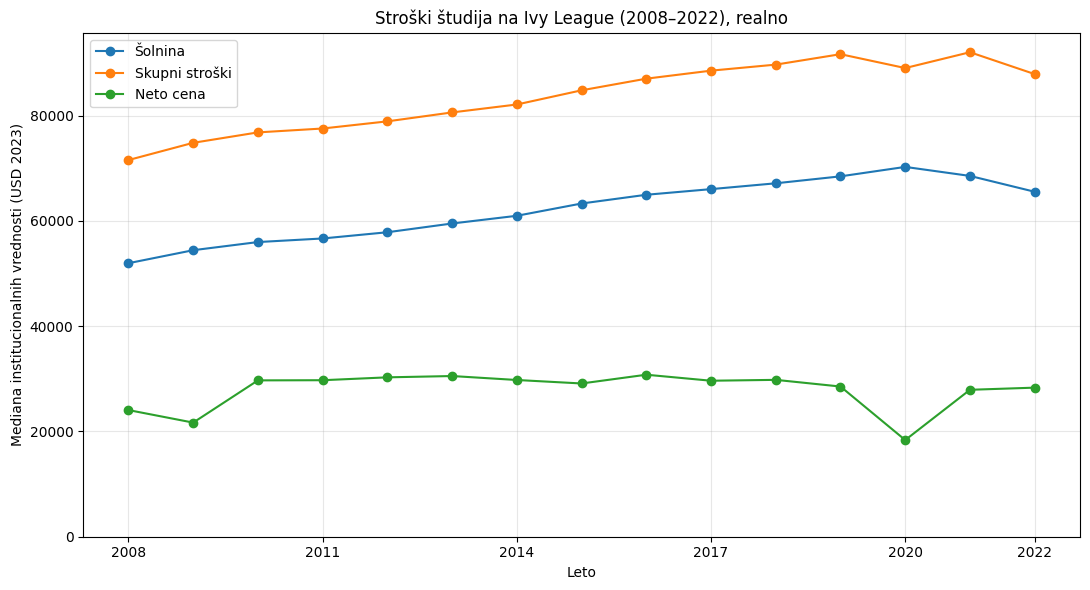

In [49]:
# RV3: Graf realnih stroškov Ivy League

plt.figure(figsize=(11, 6))

# Trije kazalniki – že prilagojeni za inflacijo
plt.plot(df_ivy_trend["leto"], df_ivy_trend["Solnina_USD_realno"],
         marker="o", label="Šolnina")
plt.plot(df_ivy_trend["leto"], df_ivy_trend["COSTT4_A_realno"],
         marker="o", label="Skupni stroški")
plt.plot(df_ivy_trend["leto"], df_ivy_trend["NPT4_PRIV_realno"],
         marker="o", label="Neto cena")

plt.title("Stroški študija na Ivy League (2008–2022), realno")
plt.xlabel("Leto")
plt.ylabel("Mediana institucionalnih vrednosti (USD 2023)")
plt.xticks([2008, 2011, 2014, 2017, 2020, 2022])
plt.ylim(bottom=0)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(mapa_figures / "RV3_ivy_stroski_neto_2008_2022_realno.png", dpi=300)
plt.show()

**Interpretacija grafa:**

- **Šolnine in skupni stroški** so se med letoma 2008 in 2022 realno večinoma povečevali, proti koncu obdobja pa nekoliko znižali.
- **Neto cene** so precej bolj nihale. Posebej izstopa velik padec leta 2020, ki mu je sledil porast leta 2021.
- **Neto cene so precej nižje od skupnih stroškov**, saj upoštevajo prejeto finančno pomoč.

**Ugotovitev:** Pri ocenjevanju dostopnosti študija ni dovolj gledati samo šolnin, ampak je treba upoštevati tudi skupne stroške in finančno pomoč.

### Metodološke omejitve RV3

- **Časovna uskladitev:** College Scorecard in IPEDS uporabljata različno označevanje let. Oznaka 2020 v analizi Ivy League pomeni študijsko leto 2020/21.
- **Neto cena:** `NPT4_PRIV` predstavlja povprečje za redne, prvič vpisane dodiplomske študente, ki prejemajo pomoč Title IV, ne za vse študente. Na grafu je prikazana mediana osmih institucionalnih povprečij.
- **Primerjava univerz:** Uporabljam neutežene mediane univerz. Pri javnih univerzah upoštevam *in-state* šolnine.
- **Spremembe vzorca:** Nabor univerz se skozi leta spreminja, zato sem dodatno preverila univerze s podatki v začetnem in končnem letu.
- **Inflacija:** Stroške sem preračunala v dolarje leta 2023 z indeksom CPI-U.
- **Obdobje:** Šolnine treh skupin primerjam za 2004–2023, stroške Ivy League pa za 2008–2022.



---



## Poglobitev RV3 – Katere univerze izstopajo pri padcu neto cen leta 2020?

In [50]:
# RV3: Preverjanje sprememb neto cen po univerzah (2019–2021)

pregled_odstopanj = df_ivy_stroski[
    df_ivy_stroski["leto"].isin([2019, 2020, 2021])
].pivot(
    index="UNITID",
    columns="leto",
    values="NPT4_PRIV"
)

# Dodam imena univerz
pregled_odstopanj["Univerza"] = pregled_odstopanj.index.map(ivy_imena)

# Izračunam odstotne spremembe
pregled_odstopanj["Sprememba 2019–2020 (%)"] = (
    (pregled_odstopanj[2020] / pregled_odstopanj[2019] - 1) * 100
).round(1)

pregled_odstopanj["Sprememba 2020–2021 (%)"] = (
    (pregled_odstopanj[2021] / pregled_odstopanj[2020] - 1) * 100
).round(1)

# Prikažem univerze od največjega padca naprej
display(
    pregled_odstopanj[
        ["Univerza", 2019, 2020, 2021,
         "Sprememba 2019–2020 (%)",
         "Sprememba 2020–2021 (%)"]
    ].sort_values("Sprememba 2019–2020 (%)")
)

leto,Univerza,2019,2020,2021,Sprememba 2019–2020 (%),Sprememba 2020–2021 (%)
UNITID,,,,,,
190150,Columbia,22823.0,12836.0,23497.0,-43.8,83.1
215062,UPenn,25046.0,14851.0,26138.0,-40.7,76.0
190415,Cornell,37042.0,29011.0,29651.0,-21.7,2.2
217156,Brown,29544.0,26308.0,27157.0,-11.0,3.2
166027,Harvard,13872.0,13259.0,19500.0,-4.4,47.1
182670,Dartmouth,32410.0,33023.0,31120.0,1.9,-5.8
130794,Yale,15296.0,16341.0,18535.0,6.8,13.4
186131,Princeton,9836.0,11080.0,8143.0,12.6,-26.5


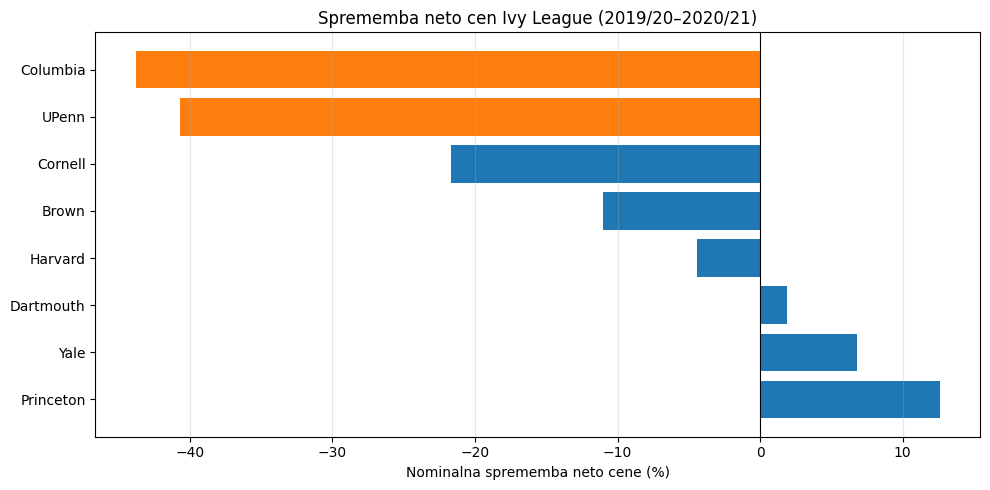

In [51]:
# RV3: Odstopanja neto cen med univerzami Ivy League

prikaz = pregled_odstopanj.sort_values(
    "Sprememba 2019–2020 (%)",
    ascending=False
)

barve = [
    "tab:orange" if ime in ["Columbia", "UPenn"]
    else "tab:blue"
    for ime in prikaz["Univerza"]
]

plt.figure(figsize=(10, 5))

plt.barh(
    prikaz["Univerza"],
    prikaz["Sprememba 2019–2020 (%)"],
    color=barve
)

plt.axvline(0, color="black", linewidth=0.8)
plt.title("Sprememba neto cen Ivy League (2019/20–2020/21)")
plt.xlabel("Nominalna sprememba neto cene (%)")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    mapa_figures / "RV3_odstopanja_neto_cen_2019_2020.png",
    dpi=300
)
plt.show()

### Ugotovitve – Padec neto cen leta 2020

- **Namen:** Na predhodnem grafu sem opazila izrazit padec mediane neto cen Ivy League leta 2020, zato sem podrobneje preverila posamezne univerze.
- **Metodologija:** Primerjala sem neto cene osmih univerz med letoma 2019 in 2021 ter izračunala nominalne odstotne spremembe.
- **Rezultati:** Največji odstotni padec leta 2020 sta imeli Columbia (−43,8 %) in UPenn (−40,7 %). Leta 2021 so se njune neto cene ponovno zvišale (+83,1 % in +76,0 %).
- **Možna razlaga:** Med pandemijo COVID-19 sta univerzi prilagodili nekatere stroške študija in finančno pomoč, kar bi lahko bilo povezano z opaženim padcem neto cen.
- **Omejitve:** Neto cene veljajo za določeno skupino študentov, ki prejemajo pomoč Title IV. Iz podatkov ne morem dokazati, da je padec povzročila pandemija, niti natančno določiti prispevka posameznih univerz k spremembi mediane.

**Viri:**
- [UPenn (2020) – Prilagoditve šolnine, pristojbin in finančne pomoči](https://penntoday.upenn.edu/announcements/revision-fall-semester-plans-regarding-campus-housing-tuition-and-fees) - Univerza je objavila zamrznitev šolnine za jesenski semester, znižanje nekaterih pristojbin ter spremembe pri bivanju in finančni pomoči.

- [Columbia (2020) – Spremembe šolnin in finančne pomoči](https://president.columbia.edu/news/message-president-bollinger-and-interim-provost-katznelson) - Univerza je poročala o omejitvi zviševanja šolnin ter povečanju finančne pomoči študentom.



---



## RV3 – Primerjava z obstoječo raziskavo College Board

In [52]:
# RV3: Primerjava z raziskavo College Board (2012–2022)

# Realna rast šolnin v mojih podatkih
p = df_rv3_trend[
    df_rv3_trend["leto"].isin([2012, 2022])
].pivot(
    index="Skupina",
    columns="leto",
    values="realna_solnina"
)

rast = ((p[2022] / p[2012] - 1) * 100).round(1)

# Primerjava z objavljenimi rezultati College Board (graf CP-4)
primerjava_cb = pd.DataFrame({
    "Vir": ["Moji podatki (IPEDS)"] * 3 + ["College Board (2022)"] * 2,
    "Skupina": [
        "Ivy League",
        "Druge zasebne neprofitne",
        "Javne štiriletne",
        "Vse zasebne neprofitne",
        "Javne štiriletne"
    ],
    "Metoda": ["Mediana"] * 3 + ["Uteženo povprečje"] * 2,
    "Realna rast (%)": [
        rast["Ivy League"],
        rast["Druge zasebne neprofitne"],
        rast["Javne štiriletne"],
        6.0,
        -1.0
    ]
})

display(primerjava_cb)

,Vir,Skupina,Metoda,Realna rast (%)
0,Moji podatki (IPEDS),Ivy League,Mediana,13.3
1,Moji podatki (IPEDS),Druge zasebne neprofitne,Mediana,0.3
2,Moji podatki (IPEDS),Javne štiriletne,Mediana,-3.4
3,College Board (2022),Vse zasebne neprofitne,Uteženo povprečje,6.0
4,College Board (2022),Javne štiriletne,Uteženo povprečje,-1.0


**Raziskava:** Ma in Pender (2022), *Trends in College Pricing and Student Aid 2022*, College Board, graf CP-4.

- **Zakaj sem jo izbrala?** Ker podobno kot moja analiza RV3 raziskuje spreminjanje šolnin na ameriških univerzah.
- **Metodologija:** College Board uporablja povprečja šolnin, utežena po številu rednih dodiplomskih študentov, jaz pa neutežene mediane univerz. Obe analizi upoštevata inflacijo.
- **Rezultati (2012–2022):** College Board ugotavlja +6 % pri zasebnih neprofitnih univerzah in −1 % pri javnih. Moji rezultati kažejo +13,3 % na Ivy League, +0,3 % pri drugih zasebnih neprofitnih in −3,4 % pri javnih.
- **Ugotovitev:** Obe analizi kažeta realno znižanje šolnin javnih univerz. Moja analiza dodatno pokaže, da je bila rast mediane šolnin Ivy League večja kot pri drugih zasebnih neprofitnih univerzah.
- **Omejitve:** Rezultati niso neposredno primerljivi zaradi različnih metod izračuna in skupin univerz.

**Vir:** [College Board (2022), graf CP-4](https://research.collegeboard.org/media/pdf/trends-in-college-pricing-student-aid-2022.pdf#page=13)



---



## Časovnica pomembnih dogodkov za visokošolsko izobraževanje v ZDA (2004–2025)

In [53]:
# Politična časovnica 2004–2025: priprava dogodkov

dogodki = [
    ("2007-09-27", "Povečanje pomoči Pell Grants", "Finančna pomoč"),
    ("2017-01-27", "Omejitve vstopa v ZDA", "Mednarodni študenti"),
    ("2020-03-27", "COVID-19 in zakon CARES", "Stroški in pomoč"),
    ("2023-06-29", "Spremembe sprejemnih politik", "Vpis"),
    ("2024-01-07", "Prenova sistema FAFSA", "Finančna pomoč"),
    ("2025-04-14", "Zamrznitev financiranja Harvarda", "Financiranje"),
    ("2025-05-22", "Harvard – omejitve mednarodnih vpisov", "Mednarodni študenti")
]

df_dogodki = pd.DataFrame(
    dogodki,
    columns=["datum", "dogodek", "podrocje"]
)

df_dogodki["datum"] = pd.to_datetime(df_dogodki["datum"])

display(df_dogodki)

,datum,dogodek,podrocje
0,2007-09-27,Povečanje pomoči Pell Grants,Finančna pomoč
1,2017-01-27,Omejitve vstopa v ZDA,Mednarodni študenti
2,2020-03-27,COVID-19 in zakon CARES,Stroški in pomoč
3,2023-06-29,Spremembe sprejemnih politik,Vpis
4,2024-01-07,Prenova sistema FAFSA,Finančna pomoč
5,2025-04-14,Zamrznitev financiranja Harvarda,Financiranje
6,2025-05-22,Harvard – omejitve mednarodnih vpisov,Mednarodni študenti


In [54]:
# Dodatne informacije o dogodkih
df_dogodki["opis"] = [
    "Razširitev zvezne pomoči Pell Grants.",
    "Omejitve vstopa za državljane določenih držav.",
    "Izredna finančna pomoč študentom in univerzam.",
    "Sodišče omeji uporabo rase pri sprejemanju študentov.",
    "Prenovljen obrazec za pridobitev finančne pomoči.",
    "Napoved zamrznitve 2,2 milijarde USD raziskovalnih sredstev.",
    "Poskus odvzema dovoljenja za mednarodne študente."
]

df_dogodki["kazalnik"] = [
    "Neto cene, finančna pomoč",
    "Mednarodni vpisi",
    "Stroški, neto cene",
    "Prijave, sprejemi, vpisi",
    "Finančna pomoč, neto cene",
    "Financiranje univerze",
    "Mednarodni vpisi"
]

df_dogodki["preverjanje"] = [
    "Ni podatkov pred dogodkom za neto cene.",
    "Ni ločenih podatkov o mednarodnih študentih.",
    "Možna opisna primerjava RV3, ne dokaz vpliva.",
    "Deloma z Aninimi podatki RV1 do 2024.",
    "Ni podatkov RV3 po letu 2023.",
    "Ni podatkov RV3 za leto 2025.",
    "Ni podatkov o vpisih za 2025."
]

display(df_dogodki)

,datum,dogodek,podrocje,opis,kazalnik,preverjanje
0,2007-09-27,Povečanje pomoči Pell Grants,Finančna pomoč,Razširitev zvezne pomoči Pell Grants.,"Neto cene, finančna pomoč",Ni podatkov pred dogodkom za neto cene.
1,2017-01-27,Omejitve vstopa v ZDA,Mednarodni študenti,Omejitve vstopa za državljane določenih držav.,Mednarodni vpisi,Ni ločenih podatkov o mednarodnih študentih.
2,2020-03-27,COVID-19 in zakon CARES,Stroški in pomoč,Izredna finančna pomoč študentom in univerzam.,"Stroški, neto cene","Možna opisna primerjava RV3, ne dokaz vpliva."
3,2023-06-29,Spremembe sprejemnih politik,Vpis,Sodišče omeji uporabo rase pri sprejemanju štu...,"Prijave, sprejemi, vpisi",Deloma z Aninimi podatki RV1 do 2024.
4,2024-01-07,Prenova sistema FAFSA,Finančna pomoč,Prenovljen obrazec za pridobitev finančne pomoči.,"Finančna pomoč, neto cene",Ni podatkov RV3 po letu 2023.
5,2025-04-14,Zamrznitev financiranja Harvarda,Financiranje,"Napoved zamrznitve 2,2 milijarde USD raziskova...",Financiranje univerze,Ni podatkov RV3 za leto 2025.
6,2025-05-22,Harvard – omejitve mednarodnih vpisov,Mednarodni študenti,Poskus odvzema dovoljenja za mednarodne študente.,Mednarodni vpisi,Ni podatkov o vpisih za 2025.


In [55]:
# Politična časovnica 2004–2025 (Plotly)

import plotly.express as px

fig = px.scatter(
    df_dogodki,
    x="datum",
    y="dogodek",
    color="podrocje",
    hover_name="dogodek",
    hover_data={
        "datum": "|%d.%m.%Y",
        "opis": True,
        "kazalnik": True,
        "preverjanje": True,
        "podrocje": False,
    },
    title="Pomembni dogodki za visokošolsko izobraževanje v ZDA (2004–2025)",
    labels={
        "datum": "Leto",
        "podrocje": "Področje"
    }
)

fig.update_traces(
    marker=dict(size=15, line=dict(width=1, color="white"))
)

fig.update_xaxes(
    range=["2004-01-01", "2025-12-31"],
    dtick="M24",
    tickformat="%Y",
    showgrid=True
)

fig.update_yaxes(title=None)

fig.update_layout(
    height=550,
    template="plotly_white",
    margin=dict(l=100, r=30, t=80, b=50),
    legend_title="Področje"
)

fig.update_yaxes(
    categoryorder="array",
    categoryarray=df_dogodki.sort_values("datum")["dogodek"].tolist()
)

fig.show()

# Shranjevanje interaktivnega grafa
fig.write_html(
    str(mapa_figures / "Politicna_casovnica_2004_2025.html")
)

# Shranjevanje še kot slika
fig.write_image(
    str(mapa_figures / "Politicna_casovnica_2004_2025.png"),
    width=1200,
    height=650,
    scale=2
)

### Ugotovitve – Časovnica političnih in zakonodajnih dogodkov

- **Namen:** Prikazati izbrane pomembne dogodke, ki predstavljajo kontekst dostopnosti, stroškov in financiranja visokošolskega izobraževanja v ZDA.
- **Metodologija:** Izbrala sem 7 dogodkov iz obdobja 2007–2025 in jih prikazala na interaktivni časovnici z opisi. Pod grafom sem navedla povezave do virov.
- **Ugotovitve:** Padec neto cen Ivy League leta 2020 časovno sovpada z obdobjem pandemije COVID-19 in sprejetjem zakona CARES.
- **Omejitve:** Časovnica prikazuje možen kontekst sprememb, ne dokazuje pa vzročnih povezav. Dogodkov iz leta 2025 ne morem neposredno preveriti s svojimi podatki. Nekateri politični ukrepi so bili tudi predmet sodnih postopkov, zato prikaz dogodka ne pomeni nujno njegove trajne veljavnosti.

**Viri:**
- **2007 – Pell Grants:** [College Cost Reduction and Access Act](https://www.govinfo.gov/app/details/PLAW-110publ84)
- **2017 – Omejitve vstopa v ZDA:** [Executive Order 13769](https://www.govinfo.gov/app/details/DCPD-201700076)
- **2020 – Zakon CARES:** [U.S. Department of Education – HEERF](https://www.ed.gov/grants-and-programs/response-programs/covid-19-grants/higher-education-emergency-relief-fund-heerf)
- **2023 – Spremembe sprejemnih politik:** [Vrhovno sodišče ZDA – Students for Fair Admissions](https://www.law.cornell.edu/supremecourt/text/20-1199)
- **2024 – Prenova FAFSA:** [U.S. Department of Education – FAFSA](https://www.ed.gov/sites/ed/files/2024-09/AFocusonImprovingtheFAFSAExperience.pdf)
- **2025 – Zamrznitev financiranja Harvarda:** [U.S. Department of Education](https://www.ed.gov/about/news/press-release/joint-task-force-combat-anti-semitism-statement-regarding-harvard-university)
- **2025 – Poskus omejitve mednarodnih vpisov na Harvard:** [Harvard International Office](https://www.hio.harvard.edu/news/2025/05/our-commitment-enrolling-international-students-and-scholars)



---



## RV5 – Zaslužki in brezposelnost glede na izobrazbo

**Raziskovalno vprašanje:** Kako se zaslužki in zaposlitvene možnosti v IT razlikujejo glede na izobrazbo?

- **Vir:** IPUMS USA, ACS 2024 (`ACS_2019_2022_2024_IT.csv`).
- **Poklici:** predhodno izbrani računalniški poklici (SOC 15-12), ne celoten IT-sektor. Izbor je bil opravljen pri pripravi podatkov.
- **Starost:** 25–64 let.
- **Izobrazba:** srednja šola/GED, bachelor's degree in master's degree.
- **Zaslužki:** utežene mediane letnih bruto zaslužkov iz zaposlitve pri zaposlenih s pozitivnim `INCWAGE`.
- **Brezposelnost:** utežene stopnje brezposelnosti med zaposlenimi in brezposelnimi s sedanjim oziroma zadnjim računalniškim poklicem.

Pri obeh analizah uporabim uteži `PERWT`. Rezultati so opisni in ne dokazujejo vzročnega vpliva izobrazbe.

In [56]:
# RV5: Preberem podatke in izberem leto 2024

df_acs_it = pd.read_csv(
    mapa / "ACS_2019_2022_2024_IT.csv",
    usecols=["YEAR", "AGE", "EDUCD", "EMPSTAT", "INCWAGE", "PERWT", "UHRSWORK"]
)
df_acs_it_2024 = df_acs_it[df_acs_it["YEAR"] == 2024].copy()

print("Zapisov iz računalniških poklicev v 2024:", len(df_acs_it_2024))

Zapisov iz računalniških poklicev v 2024: 65474




---



### Preverjanje vrednosti INCWAGE v podatkih ACS (2024)

In [57]:
# RV5: Preverjanje vrednosti INCWAGE (ACS 2024)

v = df_acs_it_2024["INCWAGE"]

print("Negativne vrednosti:", (v < 0).sum())
print("Ničelne vrednosti:", (v == 0).sum())
print("Manjkajoče vrednosti:", v.isna().sum())
print("Koda 999998:", (v == 999998).sum())
print("Koda 999999:", (v == 999999).sum())

print("\nKatere negativne vrednosti se pojavijo?")
print(v[v < 0].value_counts())

Negativne vrednosti: 0
Ničelne vrednosti: 6521
Manjkajoče vrednosti: 0
Koda 999998: 0
Koda 999999: 0

Katere negativne vrednosti se pojavijo?
Series([], Name: count, dtype: int64)


- V pripravljenih podatkih za leto 2024 ni bilo negativnih, manjkajočih ali preverjenih posebnih neveljavnih vrednosti.
- Pojavi se 6.521 ničelnih vrednosti (`INCWAGE = 0`), kar pomeni odsotnost zaslužka iz plač oziroma zaposlitve, ne nujno odsotnosti drugih dohodkov.
- Pri analizi zaslužkov izberem zaposlene s pozitivnim `INCWAGE`.
- Pri analizi brezposelnosti ne uporabljam filtra `INCWAGE > 0`.



---



In [58]:
# RV5: Izberem zaposlene in tri izobrazbene skupine

izobrazba_kode = {
    63: "Srednja šola / GED", 64: "Srednja šola / GED",
    101: "Bachelor's degree", 114: "Master's degree"
}

# Pogoji: starost 25–64 let, zaposlenost, izobrazba, pozitivni zaslužki (izključim ničelne vrednosti), pozitivna utež
maska = (
    df_acs_it_2024["AGE"].between(25, 64)
    & (df_acs_it_2024["EMPSTAT"] == 1)
    & (df_acs_it_2024["INCWAGE"] > 0)
    & (df_acs_it_2024["PERWT"] > 0)
    & (df_acs_it_2024["EDUCD"].isin(izobrazba_kode))
)

# Nova tabela - izberem ustrezne osebe glede na pogoje
df_rv5 = df_acs_it_2024.loc[maska].copy()

df_rv5["Izobrazba"] = df_rv5["EDUCD"].map(izobrazba_kode)
vrstni_red = ["Srednja šola / GED", "Bachelor's degree", "Master's degree"]

print("Zapisi po izobrazbi:")
print(df_rv5["Izobrazba"].value_counts().reindex(vrstni_red))
print("Skupaj:", len(df_rv5))

Zapisi po izobrazbi:
Izobrazba
Srednja šola / GED     2563
Bachelor's degree     23398
Master's degree       11401
Name: count, dtype: int64
Skupaj: 37362


In [59]:
# RV5: Izračun uteženih median letnih zaslužkov po izobrazbi
# PERWT - upošteva, koliko ljudi v populaciji predstavlja posamezni zapis
# Dodatno preverim rezultate pri zaposlenih z vsaj 35 običajnimi urami tedensko

def utezena_mediana(vrednosti, utezi):
    indeksi = np.argsort(vrednosti)
    zneski = np.asarray(vrednosti)[indeksi]        # Razvrsti zaslužke (vrednosti) od najnižjega do najvišjega
    utezi_urejeno = np.asarray(utezi)[indeksi]     # Uteži v istem vrstnem redu
    polovica = utezi_urejeno.sum() / 2             # Polovica vsote uteži
    return zneski[np.searchsorted(np.cumsum(utezi_urejeno), polovica)]  # Utežena mediana

# Izračun za vsako izobrazbeno skupino
rezultati = []

for izobrazba in vrstni_red:
    # zaposleni s to izobrazbo
    podatki = df_rv5[df_rv5["Izobrazba"] == izobrazba]

    # zaposleni ki delajo običajno vsaj 35 ur tedensko
    podatki_35 = podatki[podatki["UHRSWORK"] >= 35]

    # izračun dveh median
    mediana = utezena_mediana(podatki["INCWAGE"], podatki["PERWT"])
    mediana_35 = utezena_mediana(podatki_35["INCWAGE"], podatki_35["PERWT"])

    rezultati.append({
        "Izobrazba": izobrazba,
        "Stevilo_oseb": len(podatki),
        "Mediana_USD": mediana,
        "Stevilo_35_ur": len(podatki_35),
        "Delez_35_ur_%": 100 * len(podatki_35) / len(podatki),
        "Mediana_USD_35_ur": mediana_35,
        "Razlika_USD": mediana_35 - mediana
    })

df_median = pd.DataFrame(rezultati)
display(df_median.round(2))

,Izobrazba,Stevilo_oseb,Mediana_USD,Stevilo_35_ur,Delez_35_ur_%,Mediana_USD_35_ur,Razlika_USD
0,Srednja šola / GED,2563,71000,2456,95.83,75000,4000
1,Bachelor's degree,23398,107000,22662,96.85,109000,2000
2,Master's degree,11401,130000,11056,96.97,130000,0


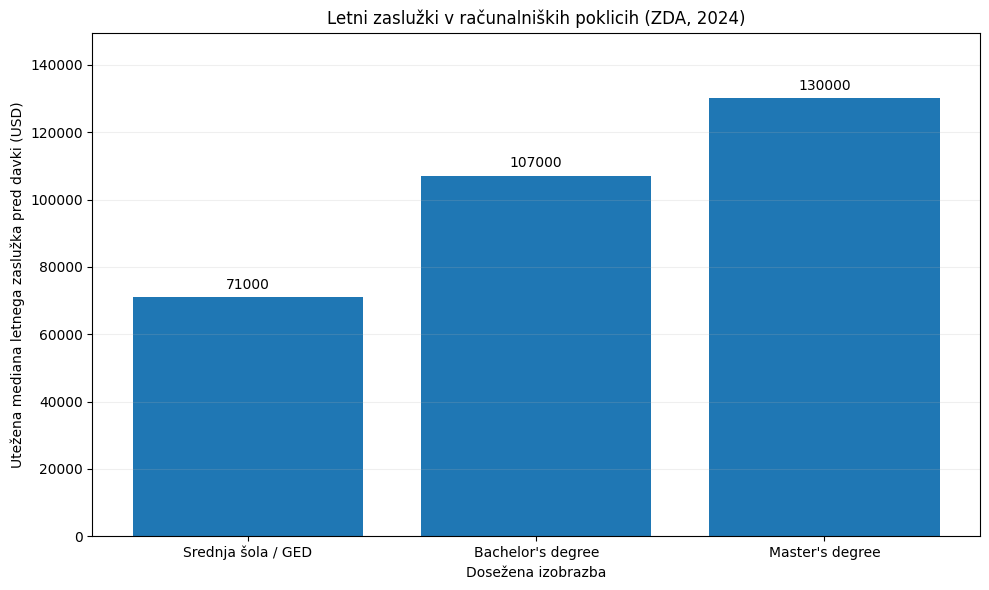

In [60]:
# RV5: Stolpčni graf uteženih median zaslužkov

plt.figure(figsize=(10, 6))
stolpci = plt.bar(df_median["Izobrazba"], df_median["Mediana_USD"])
plt.bar_label(stolpci, fmt="%.0f", padding=4)  # Zneski nad stolpci

plt.title("Letni zaslužki v računalniških poklicih (ZDA, 2024)")
plt.xlabel("Dosežena izobrazba")
plt.ylabel("Utežena mediana letnega zaslužka pred davki (USD)")
plt.ylim(0, df_median["Mediana_USD"].max() * 1.15)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

# shrani graf
plt.savefig(mapa_figures / "RV5_it_zasluzki_izobrazba_2024.png", dpi=300)
plt.show()

### Ugotovitve in omejitve – zaslužki (RV5)

**Glavne ugotovitve:**
- Med zaposlenimi v izbranih računalniških poklicih imajo osebe z višjo izobrazbo višje utežene mediane letnih zaslužkov:
  - Srednja šola/GED: **71.000 USD**
  - Bachelor's degree: **107.000 USD**
  - Master's degree: **130.000 USD**
- Razlika med medianama skupin bachelor's degree in srednja šola/GED znaša **36.000 USD** letno.
- Razlike v zaslužkih so povezane z izobrazbo, vendar to še ne pomeni, da jih povzroča sama izobrazba.

**Preverjanje občutljivosti glede na delovne ure:**
- V vseh treh izobrazbenih skupinah več kot 95 % zapisov predstavljajo zaposleni, ki običajno delajo vsaj 35 ur tedensko.
- Po omejitvi na te zaposlene se mediana pri srednji šoli/GED zviša na **75.000 USD**, pri bachelor's degree na **109.000 USD**, pri master's degree pa ostane **130.000 USD**.
- Glavna ugotovitev ostane enaka – zaposleni z višjo izobrazbo imajo višje mediane zaslužkov.

**Omejitve:**
- Analiza vključuje zaposlene s pozitivnimi zaslužki, ne pa vseh oseb s posamezno izobrazbo.
- `INCWAGE` meri bruto zaslužke iz zaposlitve v zadnjih 12 mesecih, ne začetnih plač.
- Podatek `UHRSWORK` prikazuje običajne tedenske ure, ne pa števila tednov dela v letu.
- Na zaslužke lahko poleg izobrazbe vplivajo tudi starost, izkušnje, vrsta poklica in drugi dejavniki.

**Vir:** IPUMS USA, ACS 2024. Zaslužki so izračunani kot utežene mediane z uporabo `PERWT`.

## RV5 – Brezposelnost glede na izobrazbo (ACS 2024)

Poleg zaslužkov primerjam še utežene stopnje brezposelnosti po izobrazbi. Uporabim podatke ACS 2024 za osebe, stare 25–64 let, s sedanjim oziroma zadnjim računalniškim poklicem (SOC 15-12).

V analizo vključim zaposlene in brezposelne ter uporabim uteži `PERWT`.

**Omejitev:** Rezultati ne prikazujejo verjetnosti prve zaposlitve v IT.

In [61]:
# RV5: Stopnja brezposelnosti glede na izobrazbo (ACS 2024)

# Pogoji: starost 25–64 let, 3 izobrazbene skupine, zaposleni (1) IN brezposelni (2), pozitivna utež
maska_brezposelnost = (
    df_acs_it_2024["AGE"].between(25, 64)
    & df_acs_it_2024["EDUCD"].isin(izobrazba_kode)
    & df_acs_it_2024["EMPSTAT"].isin([1, 2])
    & (df_acs_it_2024["PERWT"] > 0)
)

df_rv5_delovna_sila = df_acs_it_2024.loc[maska_brezposelnost].copy()
df_rv5_delovna_sila["Izobrazba"] = df_rv5_delovna_sila["EDUCD"].map(izobrazba_kode)

# Izračun za vsako izobrazbeno skupino
rezultati_brezposelnost = []

for izobrazba in vrstni_red:
    # ljudje s to izobrazbo
    podatki = df_rv5_delovna_sila[df_rv5_delovna_sila["Izobrazba"] == izobrazba]

    zaposleni = podatki[podatki["EMPSTAT"] == 1]
    brezposelni = podatki[podatki["EMPSTAT"] == 2]

    # Seštejem uteži zaposlenih in brezposelnih
    utezeni_zaposleni = zaposleni["PERWT"].sum()
    utezeni_brezposelni = brezposelni["PERWT"].sum()

    # Izračunam uteženo stopnjo brezposelnosti
    stopnja = 100 * utezeni_brezposelni / (utezeni_zaposleni + utezeni_brezposelni)

    rezultati_brezposelnost.append({
        "Izobrazba": izobrazba,
        "Zaposleni": len(zaposleni),
        "Brezposelni": len(brezposelni),
        "Skupaj": len(podatki),
        "Utezeni_zaposleni": utezeni_zaposleni,
        "Utezeni_brezposelni": utezeni_brezposelni,
        "Stopnja_brezposelnosti_%": stopnja
    })

# Pripravim preglednico rezultatov
pregled_brezposelnosti = pd.DataFrame(rezultati_brezposelnost).set_index("Izobrazba")

# Ohranim ime, ki jo uporablja naslednja celica za graf
utezeni_status = pregled_brezposelnosti[
    ["Utezeni_zaposleni", "Utezeni_brezposelni", "Stopnja_brezposelnosti_%"]
]

display(pregled_brezposelnosti.round(2))

# Preverim, ali so upoštevani vsi zapisi
assert pregled_brezposelnosti["Skupaj"].sum() == len(df_rv5_delovna_sila)

,Zaposleni,Brezposelni,Skupaj,Utezeni_zaposleni,Utezeni_brezposelni,Stopnja_brezposelnosti_%
Izobrazba,,,,,,
Srednja šola / GED,2649,136,2785,288928.0,13692.0,4.52
Bachelor's degree,23724,666,24390,2491895.0,71733.0,2.80
Master's degree,11522,301,11823,1245945.0,31585.0,2.47


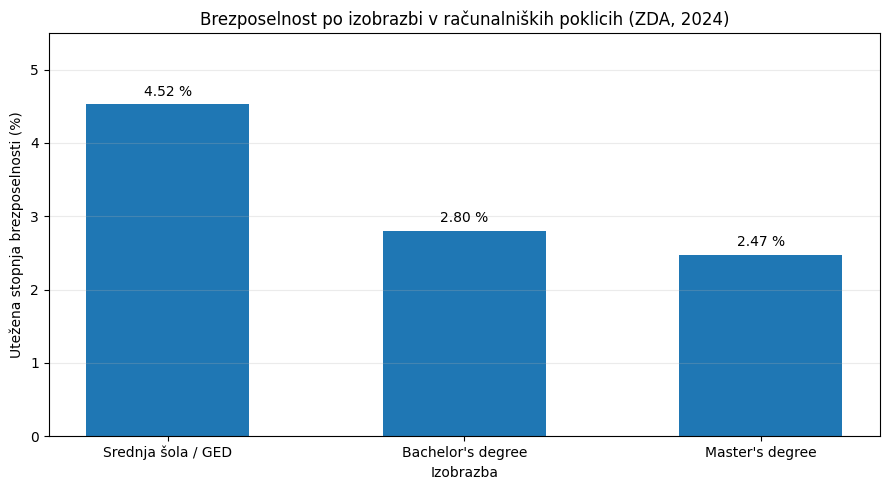

In [62]:
# RV5: Stolpčni graf uteženih stopenj brezposelnosti

stopnje = utezeni_status["Stopnja_brezposelnosti_%"]

plt.figure(figsize=(9, 5))
stolpci = plt.bar(stopnje.index, stopnje.values, width=0.55)
plt.bar_label(stolpci, fmt="%.2f %%", padding=4)  # Odstotki nad stolpci

plt.title("Brezposelnost po izobrazbi v računalniških poklicih (ZDA, 2024)")
plt.xlabel("Izobrazba")
plt.ylabel("Utežena stopnja brezposelnosti (%)")
plt.ylim(0, 5.5)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(mapa_figures / "RV5_brezposelnost_izobrazba_2024.png", dpi=300)
plt.show()

### Ugotovitve in omejitve – brezposelnost (RV5)

**Glavne ugotovitve:**
- Najvišja utežena stopnja brezposelnosti je pri skupini s srednjo šolo/GED (**4,52 %**).
- Pri bachelor's degree znaša **2,80 %**, pri master's degree pa **2,47 %**.
- Razlika v stopnji brezposelnosti med srednjo šolo/GED in bachelor's degree znaša **1,72 odstotne točke**, med bachelor's in master's degree pa **0,33 odstotne točke**.
- V obravnavani skupini računalniških poklicev je torej višja izobrazba povezana z nižjo opaženo brezposelnostjo.

**Omejitve:**
- Analiza se nanaša na osebe s sedanjim oziroma zadnjim računalniškim poklicem, ne na vse, ki želijo prvič delati v IT.
- Razlike so opisne. Ne dokazujejo, da višja izobrazba povzroča nižjo brezposelnost, njihova statistična značilnost pa še ni bila preverjena.

**Vir:** IPUMS USA, ACS 2024; uteži `PERWT`.



---



### RV5 – Zaslužki glede na starost in izobrazbo

V tem delu analiziram, kako se zaslužki v računalniških poklicih razlikujejo glede na **starost in izobrazbo**. Uporabim podatke ACS 2024 in izračunam utežene mediane za 8 starostnih ter 3 izobrazbene skupine.

Rezultate prikažem z interaktivnim grafom.

*Opomba: Podatki prikazujejo različne starostne skupine v letu 2024, ne gibanja zaslužkov istih oseb skozi čas.*

In [63]:
# RV5: Priprava petletnih starostnih skupin

# Starostne meje: 25–29, 30–34, ..., 60–64
meje = list(range(25, 66, 5))
oznake = [f"{x}–{x+4}" for x in range(25, 65, 5)]

df_rv5["Starostna_skupina"] = pd.cut(
    df_rv5["AGE"],
    bins=meje,
    labels=oznake,
    right=False     # zgornja meja intervala ni vključena
)

# Neuteženo število zapisov po starosti in izobrazbi
stevila = (
    df_rv5
    .groupby(["Starostna_skupina", "Izobrazba"], observed=False)
    .size()
    .unstack(fill_value=0)        # pretvori rezultate v preglednico
    .reindex(columns=vrstni_red)  # stolpce razvrsti po dogovorjenem vrstnem redu
)

print("Število vzorčnih zapisov po skupinah:")
display(stevila)

print("Najmanjša skupina:", stevila.min().min())
print("Skupaj zapisov:", stevila.to_numpy().sum())

assert stevila.to_numpy().sum() == len(df_rv5)

Število vzorčnih zapisov po skupinah:


Izobrazba,Srednja šola / GED,Bachelor's degree,Master's degree
Starostna_skupina,,,
25–29,343,4164,1202
30–34,349,4003,1872
35–39,332,3471,1845
40–44,360,3214,1788
45–49,283,2512,1485
50–54,310,2397,1321
55–59,311,2075,1090
60–64,275,1562,798


Najmanjša skupina: 275
Skupaj zapisov: 37362


- Analiziram 24 kombinacij (8 starostnih × 3 izobrazbene skupine).
- Najmanjša skupina ima 275 neuteženih vzorčnih zapisov, zato starostnih skupin nisem dodatno združevala.
- Skupno 37.362 zapisov je skladno z osnovno analizo zaslužkov. Število vzorčnih zapisov ne predstavlja ocenjenega števila oseb v populaciji.

In [64]:
# RV5: Utežene mediane zaslužkov po starosti in izobrazbi

# Izračun median za vseh 24 kombinacij starosti in izobrazbe
rezultati_starost = []

for (starost, izobrazba), skupina in df_rv5.groupby(
    ["Starostna_skupina", "Izobrazba"],   # .groupby() razdeli podatke glede na dve spremenljivki hkrati
    observed=True
):
    rezultati_starost.append({
        "Starostna_skupina": starost,
        "Izobrazba": izobrazba,
        "Stevilo_oseb": len(skupina),
        "Mediana_USD": utezena_mediana(skupina["INCWAGE"], skupina["PERWT"])
    })

# tabela
df_starost_izobrazba = pd.DataFrame(rezultati_starost)

# Določim vrstni red izobrazbenih skupin
df_starost_izobrazba["Izobrazba"] = pd.Categorical(
    df_starost_izobrazba["Izobrazba"],
    categories=vrstni_red,
    ordered=True
)

# Uredim rezultate
df_starost_izobrazba = (
    df_starost_izobrazba
    .sort_values(["Starostna_skupina", "Izobrazba"])    # uredi vrstice najprej po starosti, nato po izobrazbi
    .reset_index(drop=True)                             # ponovno oštevilči vrstice od 0 naprej
)

# Kontrola števila zapisov
assert df_starost_izobrazba["Stevilo_oseb"].sum() == len(df_rv5)

# Preglednico uredim za lažjo primerjavo rezultatov
preglednica_median = df_starost_izobrazba.pivot(
    index="Starostna_skupina",
    columns="Izobrazba",
    values="Mediana_USD"
)

display(preglednica_median)

Izobrazba,Srednja šola / GED,Bachelor's degree,Master's degree
Starostna_skupina,,,
25–29,56000,89000,100000
30–34,59000,100000,120000
35–39,71000,110000,130000
40–44,80000,118000,131000
45–49,88000,120000,140000
50–54,80000,122000,140000
55–59,80000,120000,141000
60–64,85000,115000,133000


In [65]:
# RV5: Interaktivni graf zaslužkov po starosti in izobrazbi

import plotly.express as px

# Pripravim podatke za graf
df_graf = df_starost_izobrazba.copy()
df_graf["Starostna_skupina"] = df_graf["Starostna_skupina"].astype(str)
df_graf["Izobrazba"] = df_graf["Izobrazba"].astype(str)

# Ustvarim interaktivni linijski graf
graf = px.line(
    df_graf,
    x="Starostna_skupina",
    y="Mediana_USD",
    color="Izobrazba",
    markers=True,
    category_orders={
        "Starostna_skupina": oznake,
        "Izobrazba": vrstni_red
    },
    hover_data={"Stevilo_oseb": True},
    title="Letni zaslužki v računalniških poklicih po starosti in izobrazbi (ZDA, 2024)",
    labels={
        "Starostna_skupina": "Starostna skupina (leta)",
        "Mediana_USD": "Utežena mediana letnega bruto zaslužka (USD)",
        "Izobrazba": "Izobrazba",
        "Stevilo_oseb": "Število zapisov"
    },
    template="plotly_white"
)

# Oblikovanje grafa
graf.update_layout(height=550)
graf.update_yaxes(rangemode="tozero")   # poskrbi da navpična os vključuje tudi ničlo

# Prikaz grafa
graf.show()

# Shranjevanje interaktivne različice kot HTML
graf.write_html(mapa_figures / "RV5_zasluzki_starost_izobrazba_2024.html")

# Shranjevanje slike PNG
graf.write_image(
    mapa_figures / "RV5_zasluzki_starost_izobrazba_2024.png",
    width=1100, height=600, scale=3
)

### RV5 – Zaslužki glede na starost in izobrazbo (ACS 2024)

**Metodologija:**
- Uporabila sem iste podatke in filtre kot pri osnovni analizi zaslužkov RV5 (ACS 2024).
- Zaslužke sem primerjala po 8 starostnih skupinah (25–64 let) in 3 stopnjah izobrazbe.
- Izračunala sem utežene mediane letnih bruto zaslužkov z uporabo PERWT.
- Najmanjša skupina vsebuje 275 neuteženih zapisov, zato starostnih razredov nisem združevala. Natančnosti ocen nisem posebej preverjala.

**Glavne ugotovitve:**
- V vseh starostnih skupinah imajo zaposleni z višjo izobrazbo višje mediane zaslužkov.
- Razlike so vidne že pri starosti 25–29 let:
  - Srednja šola/GED: **56.000 USD**
  - Bachelor's degree: **89.000 USD**
  - Master's degree: **100.000 USD**
- Razlika med skupinama bachelor's degree in srednja šola/GED znaša od **30.000 do 42.000 USD** letno, odvisno od starostne skupine.
- Pri vseh treh stopnjah izobrazbe so mediane v večini starejših starostnih skupin višje kot pri najmlajših, vendar se ne povečujejo enakomerno.

**Omejitve:**
- Graf primerja različne posameznike, ne spremlja istih ljudi skozi njihovo kariero.
- Ta analiza vključuje samo zaposlene s pozitivnimi zaslužki, zato ne omogoča ocene verjetnosti zaposlitve v IT.
- Razlik v zaslužkih ne moremo pripisati samo izobrazbi, saj nanje vplivajo tudi drugi dejavniki.

**Povezava z RV6:**

Rezultati bodo uporabni kot okvirna podlaga za kasnejšo finančno simulacijo različnih izobraževalnih poti. Pri tem bo treba upoštevati, da prikazane mediane niso napovedi prihodnjih zaslužkov posameznika.

In [66]:
# RV5: Shranjevanje rezultatov po starosti in izobrazbi

mapa_rezultati = mapa / "data" / "processed"
mapa_rezultati.mkdir(parents=True, exist_ok=True)

df_starost_izobrazba.to_csv(
    mapa_rezultati / "RV5_zasluzki_starost_izobrazba_2024.csv",
    index=False,
    encoding="utf-8-sig"
)

print("CSV uspešno shranjen.")
print("Število vrstic:", len(df_starost_izobrazba))

CSV uspešno shranjen.
Število vrstic: 24
